In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if files:
        print("  Files:", files[:5])

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/srujanamannepuli
/kaggle/input/datasets/srujanamannepuli/aligned
/kaggle/input/datasets/srujanamannepuli/aligned/Fake
/kaggle/input/datasets/srujanamannepuli/aligned/Fake/id16_id3_0003
  Files: ['frame_0196.jpg', 'frame_0202.jpg', 'frame_0199.jpg', 'frame_0217.jpg', 'frame_0235.jpg']
/kaggle/input/datasets/srujanamannepuli/aligned/Fake/id48_id41_0003
  Files: ['frame_0265.jpg', 'frame_0270.jpg', 'frame_0263.jpg', 'frame_0268.jpg', 'frame_0266.jpg']
/kaggle/input/datasets/srujanamannepuli/aligned/Fake/id27_id28_0008
  Files: ['frame_0067.jpg', 'frame_0052.jpg', 'frame_0073.jpg', 'frame_0058.jpg', 'frame_0056.jpg']
/kaggle/input/datasets/srujanamannepuli/aligned/Fake/id41_id45_0001
  Files: ['frame_0304.jpg', 'frame_0297.jpg', 'frame_0308.jpg', 'frame_0305.jpg', 'frame_0307.jpg']
/kaggle/input/datasets/srujanamannepuli/aligned/Fake/id53_id50_0005
  Files: ['frame_0413.jpg', 'frame_0071.jpg', 'frame_0415.jpg', 'frame_0072.jpg', '

In [2]:
import os

ALIGNED_ROOT = "/kaggle/input/datasets/srujanamannepuli/aligned"

REAL_DIR = os.path.join(ALIGNED_ROOT, "Real")
FAKE_DIR = os.path.join(ALIGNED_ROOT, "Fake")

print("Real exists:", os.path.exists(REAL_DIR))
print("Fake exists:", os.path.exists(FAKE_DIR))

print("Real videos/folders:", len(os.listdir(REAL_DIR)))
print("Fake videos/folders:", len(os.listdir(FAKE_DIR)))

Real exists: True
Fake exists: True
Real videos/folders: 888
Fake videos/folders: 5639


In [3]:
import os

real_video = os.listdir(REAL_DIR)[0]
real_video_dir = os.path.join(REAL_DIR, real_video)

print("Sample folder:", real_video_dir)
print("Images:", os.listdir(real_video_dir)[:5])

Sample folder: /kaggle/input/datasets/srujanamannepuli/aligned/Real/00114
Images: ['frame_0333.jpg', 'frame_0282.jpg', 'frame_0007.jpg', 'frame_0024.jpg', 'frame_0096.jpg']


In [4]:
from PIL import Image

sample_image_name = os.listdir(real_video_dir)[0]
sample_image_path = os.path.join(
    real_video_dir,
    sample_image_name
)

img = Image.open(sample_image_path)

print("Image size:", img.size)
print("Mode:", img.mode)

Image size: (224, 224)
Mode: RGB


In [5]:
import numpy as np
import pywt
from PIL import Image

In [6]:
def rgb_dwt(image):
    """
    Apply 2D Haar DWT independently to R, G, B channels.

    Returns:
        LL, LH, HL, HH
        Each shape = (112, 112, 3)
    """

    image = np.asarray(image).astype(np.float32)

    LL_channels = []
    LH_channels = []
    HL_channels = []
    HH_channels = []

    for c in range(3):

        channel = image[:, :, c]

        ll, (lh, hl, hh) = pywt.dwt2(
            channel,
            "haar"
        )

        LL_channels.append(ll)
        LH_channels.append(lh)
        HL_channels.append(hl)
        HH_channels.append(hh)

    LL = np.stack(LL_channels, axis=-1)
    LH = np.stack(LH_channels, axis=-1)
    HL = np.stack(HL_channels, axis=-1)
    HH = np.stack(HH_channels, axis=-1)

    return LL, LH, HL, HH

In [7]:
sample_img = np.array(
    Image.open(sample_image_path).convert("RGB")
)

LL, LH, HL, HH = rgb_dwt(sample_img)

print("Input:", sample_img.shape)
print("LL:", LL.shape)
print("LH:", LH.shape)
print("HL:", HL.shape)
print("HH:", HH.shape)

Input: (224, 224, 3)
LL: (112, 112, 3)
LH: (112, 112, 3)
HL: (112, 112, 3)
HH: (112, 112, 3)


In [10]:
def weighted_frequency_fusion(
    LL,
    LH,
    HL,
    HH,
    ll_weight=0.40,
    lh_weight=0.20,
    hl_weight=0.20,
    hh_weight=0.20
):
    """
    Weighted fusion of RGB DWT subbands.

    Input:
        LL, LH, HL, HH -> (112, 112, 3)

    Output:
        Fused frequency representation -> (224, 224, 3)
    """

    fused = (
        ll_weight * LL +
        lh_weight * LH +
        hl_weight * HL +
        hh_weight * HH
    )

    # Normalize to 0–255
    fused_min = fused.min()
    fused_max = fused.max()

    fused = (
        (fused - fused_min) /
        (fused_max - fused_min + 1e-8)
    ) * 255.0

    fused = fused.astype(np.uint8)

    # Resize back to 224 × 224
    fused_image = Image.fromarray(fused)
    fused_image = fused_image.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    return np.array(fused_image)

In [11]:
dwt_fused = weighted_frequency_fusion(
    LL,
    LH,
    HL,
    HH
)

print("DWT fused shape:", dwt_fused.shape)
print("Data type:", dwt_fused.dtype)
print(
    "Range:",
    dwt_fused.min(),
    "to",
    dwt_fused.max()
)

DWT fused shape: (224, 224, 3)
Data type: uint8
Range: 2 to 253


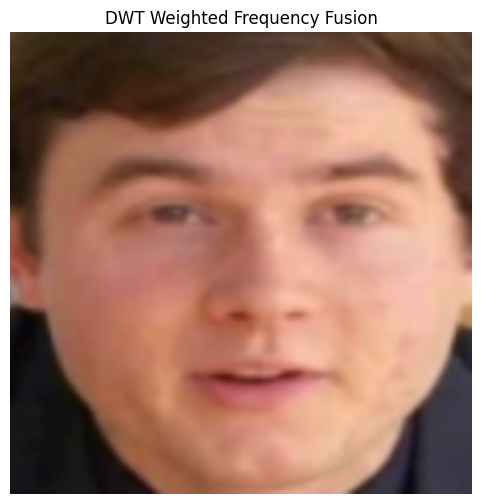

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(dwt_fused)
plt.axis("off")
plt.title("DWT Weighted Frequency Fusion")
plt.show()

In [13]:
import os
import numpy as np
import pandas as pd
import pywt
from PIL import Image
from tqdm import tqdm

# =========================================================
# 1. Paths
# =========================================================

ALIGNED_ROOT = "/kaggle/input/datasets/srujanamannepuli/aligned"

DWT_ROOT = "/kaggle/working/dwt_fused_faces"

REAL_DWT = os.path.join(DWT_ROOT, "Real")
FAKE_DWT = os.path.join(DWT_ROOT, "Fake")

os.makedirs(REAL_DWT, exist_ok=True)
os.makedirs(FAKE_DWT, exist_ok=True)

CHECKPOINT_PATH = "/kaggle/working/dwt_processing_checkpoint.csv"

print("DWT output:", DWT_ROOT)

DWT output: /kaggle/working/dwt_fused_faces


In [14]:
def rgb_dwt(image):
    """
    RGB Haar DWT.
    Input  : (224, 224, 3)
    Output : LL, LH, HL, HH
             each (112, 112, 3)
    """

    image = np.asarray(image).astype(np.float32)

    LL_channels = []
    LH_channels = []
    HL_channels = []
    HH_channels = []

    for c in range(3):

        channel = image[:, :, c]

        ll, (lh, hl, hh) = pywt.dwt2(
            channel,
            "haar"
        )

        LL_channels.append(ll)
        LH_channels.append(lh)
        HL_channels.append(hl)
        HH_channels.append(hh)

    LL = np.stack(LL_channels, axis=-1)
    LH = np.stack(LH_channels, axis=-1)
    HL = np.stack(HL_channels, axis=-1)
    HH = np.stack(HH_channels, axis=-1)

    return LL, LH, HL, HH


def weighted_frequency_fusion(
    LL,
    LH,
    HL,
    HH,
    ll_weight=0.40,
    lh_weight=0.20,
    hl_weight=0.20,
    hh_weight=0.20
):
    """
    Weighted fusion of DWT subbands.
    Output: 224 x 224 x 3
    """

    fused = (
        ll_weight * LL +
        lh_weight * LH +
        hl_weight * HL +
        hh_weight * HH
    )

    fused_min = fused.min()
    fused_max = fused.max()

    fused = (
        (fused - fused_min) /
        (fused_max - fused_min + 1e-8)
    ) * 255.0

    fused = np.clip(
        fused,
        0,
        255
    ).astype(np.uint8)

    fused_image = Image.fromarray(fused)

    fused_image = fused_image.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    return np.array(fused_image)

In [15]:
if os.path.exists(CHECKPOINT_PATH):

    checkpoint_df = pd.read_csv(
        CHECKPOINT_PATH
    )

    processed_images = set(
        checkpoint_df["image_path"].astype(str)
    )

    results = checkpoint_df.to_dict(
        "records"
    )

    print(
        "Resuming from",
        len(processed_images),
        "processed images."
    )

else:

    processed_images = set()
    results = []

    print("Starting DWT processing from beginning.")

Starting DWT processing from beginning.


In [16]:
SAVE_EVERY = 500

image_counter = 0

for label in ["Real", "Fake"]:

    input_label_dir = os.path.join(
        ALIGNED_ROOT,
        label
    )

    output_label_dir = (
        REAL_DWT
        if label == "Real"
        else FAKE_DWT
    )

    video_folders = sorted(
        os.listdir(input_label_dir)
    )

    for video_id in tqdm(
        video_folders,
        desc=f"DWT {label}"
    ):

        input_video_dir = os.path.join(
            input_label_dir,
            video_id
        )

        if not os.path.isdir(input_video_dir):
            continue

        output_video_dir = os.path.join(
            output_label_dir,
            video_id
        )

        os.makedirs(
            output_video_dir,
            exist_ok=True
        )

        image_files = [
            f for f in os.listdir(input_video_dir)
            if f.lower().endswith(".jpg")
        ]

        for image_name in image_files:

            image_path = os.path.join(
                input_video_dir,
                image_name
            )

            # ---------------------------------------------
            # Resume
            # ---------------------------------------------

            if image_path in processed_images:
                continue

            output_path = os.path.join(
                output_video_dir,
                image_name
            )

            try:

                # -----------------------------------------
                # Read aligned face
                # -----------------------------------------

                image = Image.open(
                    image_path
                ).convert("RGB")

                # -----------------------------------------
                # RGB Haar DWT
                # -----------------------------------------

                LL, LH, HL, HH = rgb_dwt(
                    image
                )

                # -----------------------------------------
                # Weighted frequency fusion
                # -----------------------------------------

                fused = weighted_frequency_fusion(
                    LL,
                    LH,
                    HL,
                    HH
                )

                # -----------------------------------------
                # Save DWT fusion image
                # -----------------------------------------

                Image.fromarray(
                    fused
                ).save(
                    output_path,
                    quality=95
                )

                results.append({

                    "image_path": image_path,

                    "output_path": output_path,

                    "label": label,

                    "video_id": video_id,

                    "image_name": image_name,

                    "status": "processed"

                })

                processed_images.add(
                    image_path
                )

                image_counter += 1

            except Exception as e:

                results.append({

                    "image_path": image_path,

                    "output_path": output_path,

                    "label": label,

                    "video_id": video_id,

                    "image_name": image_name,

                    "status": f"error: {str(e)}"

                })

            # ---------------------------------------------
            # Checkpoint
            # ---------------------------------------------

            if image_counter > 0 and image_counter % SAVE_EVERY == 0:

                checkpoint_df = pd.DataFrame(
                    results
                )

                checkpoint_df.to_csv(
                    CHECKPOINT_PATH,
                    index=False
                )

                print(
                    f"\nCheckpoint saved: "
                    f"{image_counter} images"
                )


# =========================================================
# Final checkpoint
# =========================================================

checkpoint_df = pd.DataFrame(
    results
)

checkpoint_df.to_csv(
    CHECKPOINT_PATH,
    index=False
)

print("\n===================================")
print("DWT PROCESSING COMPLETED")
print("===================================")

print(
    "Total processed:",
    len(processed_images)
)

print(
    "Output:",
    DWT_ROOT
)

print(
    "Checkpoint:",
    CHECKPOINT_PATH
)

DWT Real:  12%|█▏        | 105/888 [00:03<00:24, 31.93it/s]


Checkpoint saved: 500 images


DWT Real:  23%|██▎       | 205/888 [00:06<00:20, 32.57it/s]


Checkpoint saved: 1000 images


DWT Real:  34%|███▍      | 305/888 [00:09<00:18, 31.16it/s]

...


Checkpoint saved: 32000 images


DWT Fake: 100%|█████████▉| 5619/5639 [03:11<00:01, 19.27it/s]


Checkpoint saved: 32500 images


DWT Fake: 100%|██████████| 5639/5639 [03:11<00:00, 29.38it/s]



DWT PROCESSING COMPLETED
Total processed: 32618
Output: /kaggle/working/dwt_fused_faces
Checkpoint: /kaggle/working/dwt_processing_checkpoint.csv


In [17]:
import os

real_count = 0
fake_count = 0

for root, dirs, files in os.walk(REAL_DWT):
    real_count += sum(f.lower().endswith(".jpg") for f in files)

for root, dirs, files in os.walk(FAKE_DWT):
    fake_count += sum(f.lower().endswith(".jpg") for f in files)

print("Real DWT images:", real_count)
print("Fake DWT images:", fake_count)
print("Total DWT images:", real_count + fake_count)

Real DWT images: 4428
Fake DWT images: 28190
Total DWT images: 32618


In [18]:
import shutil
import os

DWT_ZIP_BASE = "/kaggle/working/celebdf_dwt_fused_faces"

print("Creating DWT archive...")

shutil.make_archive(
    DWT_ZIP_BASE,
    "zip",
    DWT_ROOT
)

DWT_ZIP = DWT_ZIP_BASE + ".zip"

print("ZIP created:", os.path.exists(DWT_ZIP))
print(
    "ZIP size (MB):",
    round(os.path.getsize(DWT_ZIP) / (1024**2), 2)
)

Creating DWT archive...
ZIP created: True
ZIP size (MB): 328.73
